##   Package Installation



In [1]:
import subprocess, sys


# ========================================================
# PACKAGE LIST
# ========================================================

packages = [
    # Core ML
    "torch",
    "torchvision",

    # HuggingFace
    "git+https://github.com/huggingface/transformers.git",
    "accelerate>=0.30.0",
    "bitsandbytes>=0.43.0",

    # Vision / Qwen utilities
    "qwen-vl-utils",
    "einops",
    "timm",

    # Image processing & YOLO
    "opencv-python",
    "Pillow",
    "ultralytics==8.4.47",

    # Notebook utilities
    "pandas",
    "matplotlib",

    # Gemini
    "google-genai",
]


# ========================================================
# INSTALL LOOP
# ========================================================

for pkg in packages:

    print(f"Installing {pkg} ...")

    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", pkg],
        capture_output=True,
        text=True,
    )

    if result.returncode != 0:
        print(f"  ⚠️  Warning: {result.stderr.strip()[-200:]}")
    else:
        print(f"  ✅ OK")


print(
    "\n✅ All packages installed. "
    # "RESTART THE KERNEL NOW, then run from Cell 2."
)

Installing torch ...
  ✅ OK
Installing torchvision ...
  ✅ OK
Installing git+https://github.com/huggingface/transformers.git ...
  ✅ OK
Installing accelerate>=0.30.0 ...
  ✅ OK
Installing bitsandbytes>=0.43.0 ...
  ✅ OK
Installing qwen-vl-utils ...
  ✅ OK
Installing einops ...
  ✅ OK
Installing timm ...
  ✅ OK
Installing opencv-python ...
  ✅ OK
Installing Pillow ...
  ✅ OK
Installing ultralytics==8.4.47 ...
  ✅ OK
Installing pandas ...
  ✅ OK
Installing matplotlib ...
  ✅ OK
Installing google-genai ...
  ✅ OK

✅ All packages installed. 


In [2]:
pip install num2words

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 6.7 MB/s eta 0:00:00
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13781 sha256=30b1cc5e65dfd0f37023d237da5e5ca71ea838467725730b0e2c61c09265e32f
  Stored in directory: /root/.cache/pip/wheels/1a/bf/a1/4cee4f7678c68c5875ca89eaccf460593539805c3906722228
Successfully built docopt
Note: you may need to restart the kernel to use updated packages.


In [3]:

!pip install -U google-genai
!pip install huggingface_hub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.2/110.2 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.6/472.6 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 63.5 MB/s eta 0:00:00
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.41.4
    Uninstalling pydantic_core-2.41.4:
      Successfully uninstalled pydantic_core-2.41.4
  Attempting uninstall: pydantic
    Found existing installation: pydantic 2.12.3
    Uninstalling pydantic-2.12.3:
      Successfully uninstalled pydantic-2.12.3
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.47.0
    Uninstalling google-auth-2.47.0:
      Successfully uninstalled google-auth-2.47.0
  

##  Download & Extract DENTEX Dataset



In [4]:
import os
import gc
import cv2
import json
import math
import time
import tempfile

import numpy             as np
import torch
import torchvision.models as tv_models
import torch.nn          as nn
import pandas            as pd
import matplotlib.pyplot as plt

from PIL              import Image
from ultralytics      import YOLO
from IPython.display  import display, Markdown
from google           import genai

from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText,
    InstructBlipProcessor,
    InstructBlipForConditionalGeneration,
    BitsAndBytesConfig,
    LlavaForConditionalGeneration,
)


# ========================================================
# DEVICE CHECK
# ========================================================

device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Device : {device}")

if torch.cuda.is_available():

    free, total = torch.cuda.mem_get_info()

    print(f"VRAM   : {free/1e9:.1f} GB free / {total/1e9:.1f} GB total")
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

else:

    print("⚠️  No GPU — models will run on CPU (very slow)")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[ERROR] `image_like_kwargs` is part of BaseImageProcessor.preprocess's signature, but not documented. Make sure to add it to the docstring of the function in /usr/local/lib/python3.12/dist-packages/transformers/image_processing_utils.py.
Device : cuda
VRAM   : 15.5 GB free / 15.6 GB total
GPU    : Tesla T4


In [5]:
from huggingface_hub import login, snapshot_download


# ========================================================
# HuggingFace LOGIN
# ========================================================

HF_TOKEN = os.environ.get("HF_TOKEN")

if HF_TOKEN:
    login(token=HF_TOKEN)


# ========================================================
# DOWNLOAD DENTEX
# ========================================================

path = snapshot_download(
    repo_id   = "ibrahimhamamci/DENTEX",
    repo_type = "dataset",
)

print(f"Dataset path : {path}")
print("✅ DENTEX ready")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Dataset path : /root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93
✅ DENTEX ready


In [6]:
import zipfile
import os


# ========================================================
# PATHS
# ========================================================

DENTEX_BASE = (
    "/root/.cache/huggingface/hub"
    "/datasets--ibrahimhamamci--DENTEX"
    "/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93"
    "/DENTEX"
)

ZIP_FILES = [
    "training_data.zip",
    "validation_data.zip",

]


# ========================================================
# EXTRACT
# ========================================================

for z in ZIP_FILES:

    zip_path = os.path.join(DENTEX_BASE, z)
    print(zip_path)
    print(f"  Extracting {z} ...")

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DENTEX_BASE)


print("✅ Extraction complete")


/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data.zip
  Extracting training_data.zip ...
/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/validation_data.zip
  Extracting validation_data.zip ...
✅ Extraction complete


## Imports & Device Check

##  Configuration



In [8]:
from pathlib import Path
from kaggle_secrets import UserSecretsClient


# ========================================================
# MODEL WEIGHTS  (edit to your Kaggle input paths)
# ========================================================

YOLO_DISEASE = (
    "/kaggle/input/models/boulesnane/yolo-disease/other/default/1/Yolo_disease.pt"
)

YOLO_TEETH = (
    "/kaggle/input/models/boulesnane/bestyoloteethfliplr0/other/default/1/best.pt"
)

UNET_SEG = (
    "/kaggle/input/models/boulesnane/unet-resnet34/pytorch/default/1/U-net_ResNet34.pth"
)

disease_model = YOLO(YOLO_DISEASE)
teeth_model   = YOLO(YOLO_TEETH)
# 
# ========================================================
# DATASET
# ========================================================

# Your validation JSON — file_name fields locate images in IMAGE_ROOT
RAW_JSON_PATH = (
    "/kaggle/input/datasets/boulesnane/best-fold5-val/best_fold5_val.json"
)

# Root folder containing DENTEX X-ray images
IMAGE_ROOT = (
    "/root/.cache/huggingface/hub"
    "/datasets--ibrahimhamamci--DENTEX"
    "/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93"
    "/DENTEX/training_data/quadrant-enumeration-disease/xrays"
)

# Where the reconstructed ground-truth file will be written
GROUND_TRUTH_JSON = "/kaggle/working/dentex_gt_reconstructed.json"


# ========================================================
# EVALUATION SUBSET
# Set to None to evaluate all images; set to N for a quick test run
# ========================================================

MAX_IMAGES = 30  


# ========================================================
# MODELS TO RUN  (comment out any you want to skip)
# ========================================================

MODELS_TO_RUN = [
    "smolvlm2",       # SmolVLM2-2.2B         4-bit  ~3 GB
    "qwen2_vl",       # Qwen2-VL-2B           fp16   ~4 GB
    "qwen25_vl",      # Qwen2.5-VL-3B         fp16   ~6 GB
    "instructblip",   # InstructBLIP-7B        4-bit  ~4 GB
    "llava",          # LLaVA-1.5-7B           4-bit  ~4 GB
]


# ========================================================
# GEMINI  (key pulled from Kaggle secrets)
# ========================================================


GEMINI_MODEL   = "gemini-2.5-flash"  

# ========================================================
# OUTPUT
# ========================================================

OUTPUT_DIR = "/kaggle/working/vlm_benchmark"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ========================================================
# SANITY CHECK
# ========================================================

for label, p in [
    ("RAW_JSON_PATH", RAW_JSON_PATH),
    # ("IMAGE_ROOT",    IMAGE_ROOT),
]:
    status = "OK" if os.path.exists(p) else "NOT FOUND"
    print(f"  [{status}]  {label}: {p}")

print()
print("✅ Config ready")
print(f"   Output dir   : {OUTPUT_DIR}")
print(f"   Models       : {MODELS_TO_RUN}")
print(f"   Max images   : {MAX_IMAGES}")
print(f"   Gemini model : {GEMINI_MODEL}")

  [OK]  RAW_JSON_PATH: /kaggle/input/datasets/boulesnane/best-fold5-val/best_fold5_val.json

✅ Config ready
   Output dir   : /kaggle/working/vlm_benchmark
   Models       : ['smolvlm2', 'qwen2_vl', 'qwen25_vl', 'instructblip', 'llava']
   Max images   : 30
   Gemini model : gemini-2.5-flash


##  Ground-Truth Annotation Reconstruction




In [9]:

# ============================================================
# CONSTANTS
# ============================================================

DISEASE_NAMES = {
    0: "Impacted",
    1: "Caries",
    2: "Periapical Lesion",
    3: "Deep Caries",
}

EXPECTED_TEETH = {q * 10 + t for q in range(1, 5) for t in range(1, 9)}
FDI_LIST       = [q * 10 + t for q in range(1, 5) for t in range(1, 9)]


# ============================================================
# HELPERS
# ============================================================

def tooth_anatomy(fdi: int) -> dict:
    q   = int(str(fdi)[0])
    pos = int(str(fdi)[1])

    jaw    = "maxillary" if q in (1, 2) else "mandibular"
    side   = "right" if q in (1, 4) else "left"
    region = "anterior" if pos <= 3 else "posterior"

    return {
        "jaw": jaw,
        "side": side,
        "region": region,
    }


def fix_image_path(raw_path: str, file_name: str) -> str:
    path = raw_path.replace(
        "training_data/training_data",
        "training_data"
    )

    path = path.replace(
        "validation_data/validation_data",
        "validation_data"
    )

    return path


def build_gt_summary(findings: list) -> str:

    disease_entries = []

    for f in sorted(findings, key=lambda x: x["fdi"]):

        meta = tooth_anatomy(f["fdi"])

        disease_entries.append({
            "fdi":     f["fdi"],
            "jaw":     meta["jaw"],
            "side":    meta["side"],
            "region":  meta["region"],
            "disease": f["disease"],
        })

   

    if not disease_entries :

        return json.dumps({
            "annotated_findings": [],
            # "missing_teeth": [],
            "note": "No pathological findings  detected.",
        }, indent=2)

    return json.dumps({
        "annotated_findings": disease_entries,
       
    }, indent=2)


# ============================================================
# LOAD RAW JSON
# ============================================================

with open(RAW_JSON_PATH) as f:
    raw_data = json.load(f)


# ============================================================
# RECONSTRUCT DATA
# ============================================================

reconstructed_d = []
skipped = []

for item in raw_data:

    file_name = item["image_info"]["file_name"]
    img_path  = fix_image_path(item["image_path"], file_name)

    if not os.path.exists(img_path):

        print(f"Not found: {file_name}")
        print(f"Path used: {img_path}")

        skipped.append(file_name)
        continue


    findings = []

    for ann in item["annotations"]:

        fdi = (
            (ann["category_id_1"] + 1) * 10
            + (ann["category_id_2"] + 1)
        )

        findings.append({
            "fdi":        fdi,
            "quadrant":   ann["category_id_1"] + 1,
            "tooth_pos":  ann["category_id_2"] + 1,
            "disease":    DISEASE_NAMES[ann["category_id_3"]],
            "disease_id": ann["category_id_3"],
            "bbox_xywh":  ann["bbox"],
            "area":       ann.get("area"),
        })

    disease_counts = {}

    for f in findings:

        disease = f["disease"]

        disease_counts[disease] = (
            disease_counts.get(disease, 0) + 1
        )

    reconstructed_d.append({
        "file_name":       file_name,
        "image_path":      img_path,
        "findings":        findings,
        "disease_summary": disease_counts,
        "gt_text":         build_gt_summary(
            findings,
        ),
    })


# ============================================================
# SAVE OUTPUT
# ============================================================

with open(GROUND_TRUTH_JSON, "w") as f:
    json.dump(reconstructed_d, f, indent=2)


# ============================================================
# SUMMARY
# ============================================================

total_anns = sum(
    len(r["findings"])
    for r in reconstructed_d
)

print("Reconstruction complete")
print(f"Images processed : {len(reconstructed_d)}")
print(f"Images skipped   : {len(skipped)}")
print(f"Total annotations: {total_anns}")

if skipped:

    print("\nSkipped files:")

    for s in skipped:
        print(f" - {s}")

print()

sample = reconstructed_d[10]

print(f"Sample — {sample['file_name']}")
print(f"Disease summary : {sample['disease_summary']}")
# print(f"Present teeth   : {len(sample['gt_present_fdis'])} detected")
# print(f"Missing teeth   : {sample['gt_missing_fdis']}")

print()
print(sample["gt_text"])

Reconstruction complete
Images processed : 151
Images skipped   : 0
Total annotations: 772

Sample — train_536.png
Disease summary : {'Caries': 5, 'Impacted': 4}

{
  "annotated_findings": [
    {
      "fdi": 12,
      "jaw": "maxillary",
      "side": "right",
      "region": "anterior",
      "disease": "Caries"
    },
    {
      "fdi": 18,
      "jaw": "maxillary",
      "side": "right",
      "region": "posterior",
      "disease": "Impacted"
    },
    {
      "fdi": 25,
      "jaw": "maxillary",
      "side": "left",
      "region": "posterior",
      "disease": "Caries"
    },
    {
      "fdi": 26,
      "jaw": "maxillary",
      "side": "left",
      "region": "posterior",
      "disease": "Caries"
    },
    {
      "fdi": 28,
      "jaw": "maxillary",
      "side": "left",
      "region": "posterior",
      "disease": "Impacted"
    },
    {
      "fdi": 36,
      "jaw": "mandibular",
      "side": "left",
      "region": "posterior",
      "disease": "Caries"
    },
    {

# TEETH JSON RECONSTRUCTION


In [10]:
import json
import os

# ── Config ────────────────────────────────────────────────────────────────────
TEETH_JSON_PATH = "/kaggle/input/datasets/boulesnane/best-fold4/fold4_val_teeth.json"
IMG_DIR   = (
    "/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots"
    "/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data"
    "/quadrant_enumeration/xrays"
)


# ── Load ──────────────────────────────────────────────────────────────────────
with open(TEETH_JSON_PATH) as f:
    records = json.load(f)

# ── Parse ─────────────────────────────────────────────────────────────────────
reconstructed_t = []

for record in records:
    file_name  = record["image_info"]["file_name"]
    image_path = os.path.join(IMG_DIR, file_name)


    detected_fdis = set()
    for ann in record["annotations"]:
        quadrant   = ann["category_id_1"] + 1 
        tooth      = ann["category_id_2"] + 1  
        fdi        = quadrant * 10 + tooth
        if fdi in EXPECTED_TEETH:
            detected_fdis.add(fdi)

    missing_fdis = EXPECTED_TEETH - detected_fdis

    reconstructed_t.append({
    "file_name":    file_name,
    "image_path":   image_path,
    "detected_fdis": sorted(detected_fdis),
    "missing_fdis":  sorted(missing_fdis),
    "gt_text": json.dumps({          # ← add this
        # "detected_fdis": sorted(detected_fdis),
        "missing_fdis":  sorted(missing_fdis),
    }, indent=2),
})
TEETH_GT_JSON     = "/kaggle/working/teeth_gt.json"   
with open(TEETH_GT_JSON, "w") as f:
    json.dump(reconstructed_t, f, indent=2)
# ── Display ───────────────────────────────────────────────────────────────────
for r in reconstructed_t[:5]:          # preview first 5 images
    print(f"\n{'─'*60}")
    print(f"File   : {r['file_name']}")
    print(f"Path   : {r['image_path']}")
    print(f"Present: {r['detected_fdis']}")
    print(f"Missing: {r['missing_fdis']}")

print(f"\n{'='*60}")
print(f"Total images processed: {len(reconstructed_t)}")


────────────────────────────────────────────────────────────
File   : train_132.png
Path   : /root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data/quadrant_enumeration/xrays/train_132.png
Present: [12, 15, 16, 18, 21, 23, 25, 26, 27, 31, 32, 33, 34, 36, 37, 41, 42, 43, 44, 46, 47]
Missing: [11, 13, 14, 17, 22, 24, 28, 35, 38, 45, 48]

────────────────────────────────────────────────────────────
File   : train_137.png
Path   : /root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data/quadrant_enumeration/xrays/train_137.png
Present: [11, 12, 13, 14, 15, 16, 17, 18, 21, 22, 23, 24, 25, 26, 27, 31, 32, 33, 34, 35, 36, 37, 38, 41, 42, 43, 44, 45, 46, 47, 48]
Missing: [28]

────────────────────────────────────────────────────────────
File   : train_138.png
Path   : /root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/

##  Load YOLO & UNet Models

In [11]:
# ========================================================
# YOLO MODELS
# ========================================================

disease_model = YOLO(YOLO_DISEASE)
teeth_model   = YOLO(YOLO_TEETH)


# ========================================================
# UNET — ResNet-34 backbone
# ========================================================

class UNetResNet(nn.Module):
    """UNet with ResNet-34 encoder for panoramic X-ray tooth segmentation."""

    def __init__(self):

        super().__init__()

        resnet = tv_models.resnet34(weights=None)

        # ── Encoder ──────────────────────────────────────
        self.enc1  = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.enc2  = nn.Sequential(resnet.maxpool, resnet.layer1)
        self.enc3  = resnet.layer2
        self.enc4  = resnet.layer3
        self.enc5  = resnet.layer4

        # ── Decoder ──────────────────────────────────────
        self.up4   = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4  = nn.Conv2d(256 + 256, 256, 3, padding=1)

        self.up3   = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3  = nn.Conv2d(128 + 128, 128, 3, padding=1)

        self.up2   = nn.ConvTranspose2d(128, 64,  2, stride=2)
        self.dec2  = nn.Conv2d(64  + 64,  64,  3, padding=1)

        self.up1   = nn.ConvTranspose2d(64,  64,  2, stride=2)
        self.dec1  = nn.Conv2d(64  + 64,  64,  3, padding=1)

        self.final = nn.Conv2d(64, 1, 1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        d4 = self.dec4(torch.cat([self.up4(e5), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return {"mask": self.final(d1)}


model_seg = UNetResNet().to(device)
model_seg.load_state_dict(torch.load(UNET_SEG, map_location=device))
model_seg.eval()


print("✅ YOLO disease model   loaded")
print("✅ YOLO teeth model     loaded")
print("✅ UNet segmentation    loaded")

✅ YOLO disease model   loaded
✅ YOLO teeth model     loaded
✅ UNet segmentation    loaded


## Shared Image Processing Utilities

In [12]:
# ============================================================
# IMPORTS
# ============================================================

import gc
import cv2
import math
import torch
import numpy as np


# ============================================================
# CONSTANTS
# ============================================================

FDI_LIST = [
    q * 10 + t
    for q in range(1, 5)
    for t in range(1, 9)
]


# ============================================================
# IMAGE PREPROCESSING
# ============================================================
def tooth_anatomy(fdi: int) -> dict:
    q   = int(str(fdi)[0])
    pos = int(str(fdi)[1])

    jaw    = "maxillary" if q in (1, 2) else "mandibular"
    side   = "right" if q in (1, 4) else "left"
    region = "anterior" if pos <= 3 else "posterior"

    return {
        "jaw": jaw,
        "side": side,
        "region": region,
    }

def preprocess_image(img_path: str):

    image = cv2.imread(img_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    original_h, original_w = image.shape[:2]

    resized = cv2.resize(
        image,
        (1280, 640)
    )

    tensor = (
        torch.tensor(resized / 255.0)
        .permute(2, 0, 1)
        .float()
        .unsqueeze(0)
        .to(device)
    )

    return image, tensor, original_h, original_w


# ============================================================
# SEGMENTATION OVERLAY
# ============================================================

def generate_segmentation_overlay(original_img: np.ndarray, tensor_img: torch.Tensor) -> np.ndarray:
    """Draw only the OUTLINE of the segmented teeth: pixels inside the teeth stay unchanged."""
    with torch.no_grad():
        pred_mask = torch.sigmoid(model_seg(tensor_img)["mask"]).squeeze().cpu().numpy()
    mask = (pred_mask > 0.5).astype(np.uint8) * 255
    mask = cv2.resize(mask, (original_img.shape[1], original_img.shape[0]), interpolation=cv2.INTER_NEAREST)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    overlay = original_img.copy()
    thickness = max(2, original_img.shape[1] // 800)          # ~3 px on a 2,800-px panoramic
    cv2.drawContours(overlay, contours, -1, (0, 255, 0), thickness)
    return overlay


# ============================================================
# BOUNDING BOX UTILITIES
# ============================================================

def xywh_to_xyxy(box):

    xc, yc, w, h = box

    x1 = xc - w / 2
    y1 = yc - h / 2

    x2 = xc + w / 2
    y2 = yc + h / 2

    return x1, y1, x2, y2


def compute_iou(box1, box2):

    x11, y11, x12, y12 = xywh_to_xyxy(box1)
    x21, y21, x22, y22 = xywh_to_xyxy(box2)

    xi1 = max(x11, x21)
    yi1 = max(y11, y21)

    xi2 = min(x12, x22)
    yi2 = min(y12, y22)

    inter_w = max(0, xi2 - xi1)
    inter_h = max(0, yi2 - yi1)

    intersection = inter_w * inter_h

    area1 = (x12 - x11) * (y12 - y11)
    area2 = (x22 - x21) * (y22 - y21)

    union = area1 + area2 - intersection

    if union == 0:
        return 0.0

    return intersection / union


def get_box_center(box):

    xc, yc, _, _ = box

    return xc, yc


def compute_center_distance(box1, box2):

    x1, y1 = get_box_center(box1)
    x2, y2 = get_box_center(box2)

    return math.sqrt(
        (x1 - x2) ** 2 +
        (y1 - y2) ** 2
    )


def compute_fusion_score(
    disease_box,
    tooth_box,
    iou_weight=0.7,
    distance_weight=0.3
):

    iou = compute_iou(
        disease_box,
        tooth_box
    )

    distance = compute_center_distance(
        disease_box,
        tooth_box
    )

    distance_score = np.exp(-distance * 10)

    fusion_score = (
        iou_weight * iou +
        distance_weight * distance_score
    )

    return fusion_score


# ============================================================
# STRUCTURED JSON GENERATION
# ============================================================

def generate_structured_json(img_path: str) -> dict:

    raw_teeth = []

    teeth_results = teeth_model.predict(
        source=img_path,
        conf=0.25,
        verbose=False
    )

    for box in teeth_results[0].boxes:

        cls = int(box.cls[0])
        conf = float(box.conf[0])

        xc, yc, w, h = map(
            float,
            box.xywhn[0]
        )

        fdi = FDI_LIST[cls]

        anatomy = tooth_anatomy(fdi)

        raw_teeth.append({

            "fdi": fdi,

            **anatomy,

            "present": True,

            "bbox": [xc, yc, w, h],

            "confidence": conf,

            "diseases": []
        })

    # ========================================================
    # REMOVE DUPLICATE TEETH
    # ========================================================

    best_teeth = {}

    for tooth in raw_teeth:

        fdi = tooth["fdi"]

        if (
            fdi not in best_teeth
            or tooth["confidence"] >
               best_teeth[fdi]["confidence"]
        ):
            best_teeth[fdi] = tooth

    teeth = list(best_teeth.values())

    # ========================================================
    # DISEASE DETECTION
    # ========================================================

    disease_detections = []

    disease_results = disease_model.predict(
        source=img_path,
        conf=0.15,
        imgsz=1024,
        verbose=False
    )

    for box in disease_results[0].boxes:

        cls = int(box.cls[0])
        conf = float(box.conf[0])

        xc, yc, w, h = map(
            float,
            box.xywhn[0]
        )

        disease_detections.append({

            "disease": DISEASE_NAMES[cls],

            "disease_id": cls,

            "confidence": conf,

            "bbox": [xc, yc, w, h]
        })

    # ========================================================
    # DISEASE ↔ TOOTH FUSION
    # ========================================================

    for disease in disease_detections:

        best_tooth = None
        best_score = -1

        for tooth in teeth:

            score = compute_fusion_score(
                disease["bbox"],
                tooth["bbox"]
            )

            if score > best_score:

                best_score = score
                best_tooth = tooth

        if best_tooth is not None:

            best_tooth["diseases"].append({

                "name": disease["disease"],

                "confidence": disease["confidence"]
            })

    # ========================================================
    # REMOVE DUPLICATE DISEASES
    # ========================================================

    for tooth in teeth:

        unique_diseases = {}

        for disease in tooth["diseases"]:

            name = disease["name"]

            if (
                name not in unique_diseases
                or disease["confidence"] >
                   unique_diseases[name]["confidence"]
            ):
                unique_diseases[name] = disease

        tooth["diseases"] = list(
            unique_diseases.values()
        )

    # ========================================================
    # SUMMARY
    # ========================================================

    detected_fdis = {
        tooth["fdi"]
        for tooth in teeth
    }

    missing_fdis = sorted(
        EXPECTED_TEETH - detected_fdis
    )

    disease_summary = {}

    for tooth in teeth:

        for disease in tooth["diseases"]:

            disease_name = disease["name"]

            disease_summary[disease_name] = (
                disease_summary.get(disease_name, 0) + 1
            )

    # ========================================================
    # FINAL STRUCTURE
    # ========================================================

    return {

        "detected_teeth":
            sorted(detected_fdis),

        "suspected_missing_teeth":
            missing_fdis,

        "disease_summary":
            disease_summary,

        "teeth":
            sorted(
                teeth,
                key=lambda x: x["fdi"]
            )
    }


# ============================================================
# VRAM CLEANUP
# ============================================================

def free_vram():

    gc.collect()

    for fn in [
        torch.cuda.empty_cache,
        torch.cuda.ipc_collect
    ]:
        try:
            fn()
        except Exception:
            pass

    try:

        free, total = torch.cuda.mem_get_info()

        print(
            f"VRAM: "
            f"{free / 1e9:.1f} GB free / "
            f"{total / 1e9:.1f} GB total"
        )

    except Exception:

        print("VRAM info unavailable")


# ============================================================
# READY
# ============================================================

print("Shared utilities ready")

Shared utilities ready


Demo image : /root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data/quadrant-enumeration-disease/xrays/train_475.png


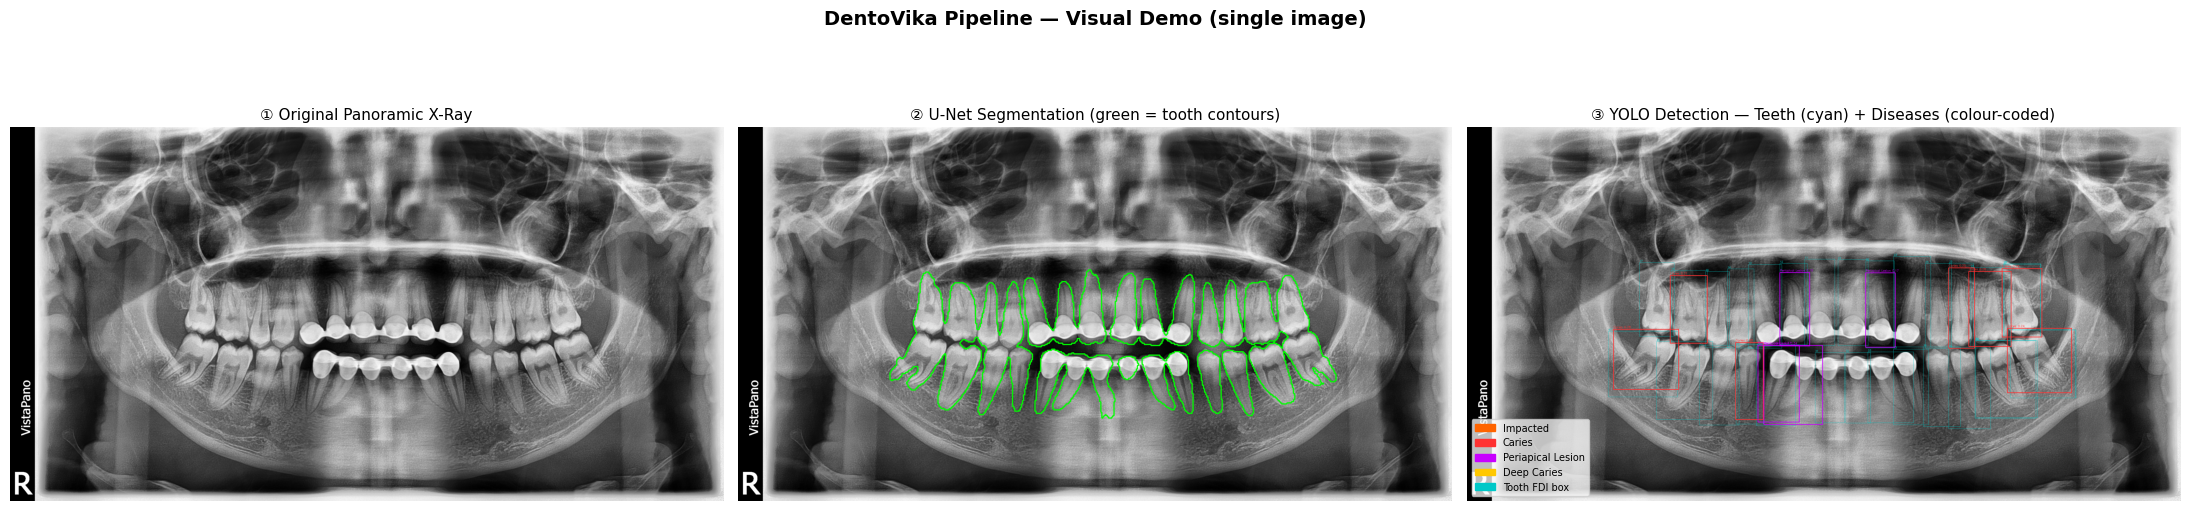

Figure saved -> /kaggle/working/demo_pipeline_output.png

④ Structured JSON  (Mode C / D prompt input)
{
  "detected_teeth": [
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    43,
    44,
    45,
    46,
    47
  ],
  "suspected_missing_teeth": [
    18,
    41,
    42,
    48
  ],
  "disease_summary": {
    "Periapical Lesion": 3,
    "Caries": 7
  },
  "teeth (first 3 shown)": [
    {
      "fdi": 11,
      "jaw": "maxillary",
      "side": "right",
      "region": "anterior",
      "present": true,
      "bbox": [
        0.4941268563270569,
        0.4690040946006775,
        0.042134106159210205,
        0.23072035610675812
      ],
      "confidence": 0.788684070110321,
      "diseases": []
    },
    {
      "fdi": 12,
      "jaw": "maxillary",
      "side": "right",
      "region": "anterior",
      "present": true,
      "bbox": [
        0

In [13]:
# ============================================================
# DEMO CELL — Visual Pipeline Output for the Examiner
# Shows: (1) original image  (2) U-Net overlay
#        (3) YOLO boxes       (4) structured JSON
# ============================================================

import os, json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Pick the first valid image from the reconstructed ground-truth ───────────
demo_entry    = reconstructed_d[0]
DEMO_IMG_PATH = demo_entry['image_path']
print(f'Demo image : {DEMO_IMG_PATH}')
assert os.path.exists(DEMO_IMG_PATH), 'Image not found — check reconstructed_d paths'

# ── 1. Preprocessing ─────────────────────────────────────────────────────────
original_img, tensor_img, orig_h, orig_w = preprocess_image(DEMO_IMG_PATH)

# ── 2. U-Net segmentation overlay ────────────────────────────────────────────
overlay_img = generate_segmentation_overlay(original_img, tensor_img)

# ── 3. YOLO predictions (disease + teeth) ────────────────────────────────────
DISEASE_COLORS = {
    'Impacted':          (255, 100,   0),
    'Caries':            (255,  50,  50),
    'Periapical Lesion': (200,   0, 255),
    'Deep Caries':       (255, 200,   0),
}

def draw_yolo_boxes(img_rgb, disease_results, teeth_results):
    out  = img_rgb.copy()
    h, w = out.shape[:2]
    # teeth boxes — thin cyan
    for box in teeth_results[0].boxes:
        cls = int(box.cls[0])
        xc, yc, bw, bh = box.xywhn[0].tolist()
        x1 = int((xc - bw/2)*w); y1 = int((yc - bh/2)*h)
        x2 = int((xc + bw/2)*w); y2 = int((yc + bh/2)*h)
        fdi = FDI_LIST[cls]
        cv2.rectangle(out, (x1,y1), (x2,y2), (0,200,200), 1)
        cv2.putText(out, str(fdi), (x1, max(y1-3,0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.32, (0,200,200), 1)
        

    # disease boxes — colour-coded, thicker

    for box in disease_results[0].boxes:
        cls  = int(box.cls[0])
        conf = float(box.conf[0])
        name = DISEASE_NAMES[cls]
        xc, yc, bw, bh = box.xywhn[0].tolist()
        x1 = int((xc - bw/2)*w); y1 = int((yc - bh/2)*h)
        x2 = int((xc + bw/2)*w); y2 = int((yc + bh/2)*h)
        color = DISEASE_COLORS.get(name, (255,255,255))
        cv2.rectangle(out, (x1,y1), (x2,y2), color, 2)
        cv2.putText(out, f'{name} {conf:.2f}', (x1, max(y1-5,0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.38, color, 1)
    return out

disease_res = disease_model.predict(source=DEMO_IMG_PATH, conf=0.15, verbose=False)
teeth_res   = teeth_model.predict(  source=DEMO_IMG_PATH, conf=0.25, verbose=False)
yolo_vis    = draw_yolo_boxes(original_img, disease_res, teeth_res)


# ── 4. Structured JSON ────────────────────────────────────────────────────────
structured = generate_structured_json(DEMO_IMG_PATH)

# ── 5. Figure: three panels side by side ─────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle('DentoVika Pipeline — Visual Demo (single image)',
             fontsize=14, fontweight='bold')

axes[0].imshow(original_img)
axes[0].set_title('① Original Panoramic X-Ray', fontsize=11)
axes[0].axis('off')

axes[1].imshow(overlay_img)
axes[1].set_title('② U-Net Segmentation (green = tooth contours)', fontsize=11)
axes[1].axis('off')

axes[2].imshow(yolo_vis)
axes[2].set_title('③ YOLO Detection — Teeth (cyan) + Diseases (colour-coded)', fontsize=11)
axes[2].axis('off')

legend_patches = [
    mpatches.Patch(color=[c/255 for c in col], label=name)
    for name, col in DISEASE_COLORS.items()
]
legend_patches.append(
    mpatches.Patch(color=(0, 200/255, 200/255), label='Tooth FDI box')
)
axes[2].legend(handles=legend_patches, loc='lower left', fontsize=7, framealpha=0.75)

plt.tight_layout()
plt.savefig('/kaggle/working/demo_pipeline_output.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved -> /kaggle/working/demo_pipeline_output.png')

# ── 6. Print structured JSON (trimmed to first 3 teeth for readability) ───────
print()
print('=' * 60)
print('④ Structured JSON  (Mode C / D prompt input)')
print('=' * 60)
display_struct = {
    'detected_teeth':          structured['detected_teeth'],
    'suspected_missing_teeth': structured['suspected_missing_teeth'],
    'disease_summary':         structured['disease_summary'],
    'teeth (first 3 shown)':   structured['teeth'][:3],
}
print(json.dumps(display_struct, indent=2))
print()
print(f"Total teeth detected : {len(structured['detected_teeth'])}")
print(f"Missing teeth        : {len(structured['suspected_missing_teeth'])}")
print(f"Disease summary      : {structured['disease_summary']}")


##  Prompt Builders (4 Modes)



In [14]:
# ========================================================
# INTERNAL HELPER — format YOLO findings into readable text
# ========================================================

def _build_findings_block(structured_json)-> tuple:

    findings = []

    for tooth in structured_json["teeth"]:

        if not tooth["diseases"]:
            continue

        header = (
            f"- Tooth {tooth['fdi']} "
            f"({tooth['jaw']} "
            f"{tooth['side']} "
            f"{tooth['region']})"
        )

        disease_lines = []

        for disease in tooth["diseases"]:

            conf = disease["confidence"]

            if conf >= 0.80:
                level = "detected"

            elif conf >= 0.50:
                level = "probable"

            else:
                level = "possible"

            disease_lines.append(
                f"    - {level} "
                f"{disease['name']} "
               
            )

        findings.append(
            header + "\n" + "\n".join(disease_lines)
        )

    findings_text = (
        "\n\n".join(findings)
        if findings
        else "No confident pathological findings."
    )

    

    if structured_json["suspected_missing_teeth"]:

        missing = ", ".join(str(x) for x in structured_json["suspected_missing_teeth"])
        missing_summary = (
            f"Teeth not detected (possibly absent / unerupted): {missing}"
        )

    else:

        missing_summary = "All teeth were detected."

    return findings_text, missing_summary


# ========================================================
# MODE A — ZERO-SHOT  (plain image, no hints)
# ========================================================

PROMPT_A = """You are a board-certified dental radiologist with 20 years of experience \
interpreting panoramic radiographs.

CLINICAL TASK:
Examine the panoramic radiograph and generate a structured dental radiology report.

STRICT REPORTING RULES:
- Report ONLY findings that are clearly visible in the image.
- Do NOT invent, assume, or hallucinate findings.
- Do NOT describe normal or healthy anatomy.
- Do NOT comment on image quality or technical factors.
- Use standard FDI tooth notation throughout.
- Maintain anatomical ordering.
- Use concise, formal radiology prose. No repetition.

OUTPUT FORMAT:

REPORT:
[Single clinical paragraph. 3-6 sentences. Anatomical order. Formal radiology language.]""".strip()


# Condensed — for InstructBLIP / SmolVLM2 (< 512 input tokens)

PROMPT_A_SHORT = PROMPT_A



# ========================================================
# MODE B — OVERLAY-ONLY  (overlay image, no JSON)
# ========================================================

PROMPT_B = """You are a board-certified dental radiologist with 20 years of experience \
interpreting panoramic radiographs.

CLINICAL TASK:
Examine the panoramic radiograph with segmentation overlay and generate a \
structured dental radiology report.
Green outlines mark the teeth detected by a segmentation model. They are only an \
anatomical guide: examine the full radiograph, including the tooth structures inside \
the outlines, the roots, periapical areas and surrounding bone, and report findings \
wherever they appear.

STRICT REPORTING RULES:
- Report ONLY findings that are clearly visible in the image.
- Do NOT invent, assume, or hallucinate findings.
- Do NOT describe normal or healthy anatomy.
- Do NOT comment on image quality, contrast, or the green outlines themselves.
- Use standard FDI tooth notation throughout.
- Maintain anatomical ordering.
- Use concise, formal radiology prose. No repetition.

OUTPUT FORMAT:

REPORT:
[Single clinical paragraph. 3-6 sentences. Anatomical order. Formal radiology language.]""".strip()


# Condensed — for InstructBLIP / SmolVLM2

PROMPT_B_SHORT = """You are a board-certified dental radiologist interpreting a panoramic radiograph.
Green outlines mark the detected teeth as a guide only; examine the whole radiograph, including inside the outlines, roots and bone.

CLINICAL TASK: Examine the image and report pathological findings only.

RULES:
- Report ONLY clearly visible pathological findings.
- Do NOT describe healthy teeth, normal anatomy, or the green outlines.
- Do NOT mention image quality or technical factors.
- Use FDI tooth notation. Anatomical order.

Write a single clinical paragraph of 3-6 sentences in formal radiology language.""".strip()


# ========================================================
# MODE C — FINDINGS-ONLY  (plain image + YOLO JSON)
# ========================================================

def build_prompt_c(sj: dict) -> str:


    findings_text, missing_summary = _build_findings_block(sj)

    return f"""You are a board-certified dental radiologist with 20 years of experience \
interpreting panoramic radiographs.

CLINICAL TASK:
Generate a structured radiology report based on the structured detections below \
and the panoramic radiograph image provided.

STRICT REPORTING RULES:
- Report ONLY findings present in the detections AND visually supported by the image.
- Do NOT invent, assume, or hallucinate any finding not listed below.
- Do NOT describe normal or healthy anatomy.
- Do NOT mention AI, confidence scores, or detection pipelines.
- Do NOT confirm missing teeth — use "not visualized".
- Use FDI tooth notation. Anatomical order.
- Use concise, formal radiology prose. No repetition.

STRUCTURED DETECTIONS:
{{findings_text}}

{{missing_summary}}

OUTPUT FORMAT:

REPORT:
[Single clinical paragraph. 3-6 sentences. Anatomical order. Formal radiology language.]""".strip().format(
        findings_text  = findings_text,
        missing_summary = missing_summary,
    )


def build_prompt_c_short(sj: dict) -> str:

    findings_text, missing_summary = _build_findings_block(sj)

    return f"""You are a board-certified dental radiologist interpreting a panoramic radiograph.

CLINICAL TASK: Report ONLY findings present in both the detections below and the image.



RULES: Do NOT invent findings. Do NOT describe healthy anatomy.
Do NOT mention AI or scores. Use FDI notation. Anatomical order.

STRUCTURED FINDINGS:
{{findings_text}}

{{missing_summary}}

Write a single clinical paragraph of 3-6 sentences.""".strip().format(
        findings_text   = findings_text,
        missing_summary = missing_summary,
    )


# ========================================================
# MODE D — FULL PIPELINE  (overlay + YOLO JSON)
# ========================================================

def build_prompt_d(sj: dict) -> str:
   
    findings_text, missing_summary = _build_findings_block(sj)

    return f"""You are a board-certified dental radiologist with 20 years of experience \
interpreting panoramic radiographs.

CLINICAL TASK:
You are provided with two inputs:
  1. A panoramic radiograph in which green outlines mark the teeth detected by a
     segmentation model (an anatomical guide only: examine the full radiograph, including
     inside the outlines, the roots, periapical areas and surrounding bone).
  2. Structured detections from a detection pipeline (teeth + disease ).

Generate a structured dental radiology report integrating both inputs.

STRICT REPORTING RULES:
- Report ONLY findings visually supported by the image AND listed in the detections.
- Do NOT invent findings not supported by both inputs.
- Do NOT describe healthy anatomy or normal structures.
- Do NOT comment on image quality, the green outlines, or the AI pipeline.
- Do NOT confirm missing teeth — use "not visualized".
- Use FDI tooth notation. Anatomical order
- Use concise, formal radiology prose. No repetition.

STRUCTURED DETECTIONS:
{{findings_text}}

{{missing_summary}}

OUTPUT FORMAT:

REPORT:
[Single clinical paragraph. 3-6 sentences. Anatomical order. Formal radiology language.]""".strip().format(
        findings_text   = findings_text,
        missing_summary = missing_summary,
    )


def build_prompt_d_short(sj: dict) -> str:
 

    findings_text, missing_summary = _build_findings_block(sj)

    return f"""You are a board-certified dental radiologist interpreting a panoramic radiograph.
Green outlines mark the detected teeth as a guide only; examine the whole radiograph, including inside the outlines, roots and bone.

CLINICAL TASK: Integrate the image and the detections below into a concise radiology report.

RULES: Report ONLY findings present in BOTH the image and the detections.
Do NOT invent findings. Do NOT describe healthy anatomy or the green outlines.
Do NOT mention AI or pipelines. Use FDI notation. Anatomical order.

STRUCTURED FINDINGS:
{{findings_text}}

{{missing_summary}}

Write a single clinical paragraph of 3-6 sentences.""".strip().format(
        findings_text   = findings_text,
        missing_summary = missing_summary,
    )


print("✅ Prompt builders ready")
print("   Standard  : PROMPT_A, PROMPT_B, build_prompt_c, build_prompt_d")
print("   Condensed : PROMPT_A_SHORT, PROMPT_B_SHORT,")
print("               build_prompt_c_short, build_prompt_d_short")

✅ Prompt builders ready
   Standard  : PROMPT_A, PROMPT_B, build_prompt_c, build_prompt_d
   Condensed : PROMPT_A_SHORT, PROMPT_B_SHORT,
               build_prompt_c_short, build_prompt_d_short


##  VLM Registry




In [15]:
#Contact us on aboulesnane@univ-constantine3.dz

print("✅ VLM Registry ready")
print("   Models available:", list(VLM_REGISTRY.keys()))

✅ VLM Registry ready
   Models available: ['smolvlm2', 'qwen2_vl', 'qwen25_vl', 'instructblip', 'llava']


In [16]:
!pip install -U openai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.1 MB/s eta 0:00:00
  Using cached httpx2-2.13.1-py3-none-any.whl.metadata (9.8 kB)
  Using cached httpcore2-2.13.1-py3-none-any.whl.metadata (26 kB)
  Using cached truststore-0.10.4-py3-none-any.whl.metadata (4.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 65.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.6/95.6 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.4/83.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.0/345.0 kB 18.7 MB/s eta 0:00:00
  Attempting uninstall: jiter
    Found existing installation: jiter 0.10.0
    Uninstalling jiter-0.10.0:
      Successfully uninstalled jiter-0.10.0
  Attempting uninstall: openai
    Found existing installation: openai 2.32.0
    Uninstalling openai-2.32.0:
      Successfully uninstalled openai-2.32.0


# Create OpenRouter client

In [17]:
from openai import OpenAI
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()



OPENROUTER_API_KEY = user_secrets.get_secret("Openrouter")

judge_client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=OPENROUTER_API_KEY,
)

## Gemini Judge

In [18]:
# ========================================================
# GEMINI CLIENT SETUP
# ========================================================



CRITERION_WEIGHTS = {
    "accuracy":       0.20,
    "completeness":   0.20,
    "localization":   0.20,
    "hallucination":  0.15,
    "missing_teeth":  0.10,
    "clarity":        0.15,
}


# ========================================================
# JUDGE PROMPT TEMPLATE
# ========================================================
# Ground truth is injected as structured JSON with two keys:
#   - annotated_findings : disease per FDI tooth
#   - missing_teeth      : FDI teeth YOLO did not detect
# ========================================================

JUDGE_PROMPT_TEMPLATE = """You are an expert dental radiologist and AI evaluation specialist.

Your task is to evaluate a VLM-generated dental radiology report against
the ground-truth provided as structured JSON.

================================================================
GROUND-TRUTH  (structured JSON)
================================================================
{gt_json}

The JSON has two sections:
  • annotated_findings  — diseases confirmed per FDI tooth number
  • missing_teeth       — FDI teeth not detected by the detection pipeline
                          (possibly absent, unerupted, or not visible)

================================================================
VLM REPORT TO EVALUATE
================================================================
{vlm_report}

================================================================
EVALUATION CRITERIA  (score each 1–10)
================================================================

1. ACCURACY (20%)
   Do the reported disease types match those in annotated_findings?
   10 = all diseases correct; 1 = completely wrong disease types.

2. COMPLETENESS (20%)
   Are all entries in annotated_findings mentioned in the report?
   10 = every GT finding covered; 1 = almost nothing mentioned.

3. LOCALIZATION (20%)
   Are the correct FDI tooth numbers from annotated_findings linked to
   the correct diseases? Are jaw (maxillary/mandibular), side (left/right),
   and region (anterior/posterior) correct for each reported tooth?
   10 = all FDI numbers and anatomy labels exactly match; 1 = all wrong.

4. HALLUCINATION (15%)
   Does the report mention findings NOT in annotated_findings?
   10 = zero hallucinations; 1 = many fabricated findings.

5. MISSING TEETH (10%)
   Does the report correctly identify or acknowledge the teeth listed
   in missing_teeth (using phrases like "not visualized", "absent",
   "not detected", or listing their FDI numbers)?
   10 = all missing teeth correctly noted; 1 = none mentioned at all.
   If missing_teeth is empty, score this 10.

6. CLARITY (15%)
   Is the report well-structured, concise, and written in formal
   radiology prose?
   10 = excellent clinical language; 1 = incoherent or very poor.

================================================================
OUTPUT FORMAT  (strict JSON only — no extra text, no markdown fences)
================================================================
{{
  "scores": {{
    "accuracy":      <int 1-10>,
    "completeness":  <int 1-10>,
    "localization":  <int 1-10>,
    "hallucination": <int 1-10>,
    "missing_teeth": <int 1-10>,
    "clarity":       <int 1-10>
  }},
  "weighted_score": <float, 1 decimal, range 1.0–10.0>,
  "reasoning": {{
    "accuracy":      "<one sentence>",
    "completeness":  "<one sentence>",
    "localization":  "<one sentence>",
    "hallucination": "<one sentence>",
    "missing_teeth": "<one sentence>",
    "clarity":       "<one sentence>"
  }},
  "summary": "<2-3 sentence overall assessment>"
}}
""".strip()



print("✅ Gemini judge ready")
print(f"   Model     : {GEMINI_MODEL}")
print(f"   Criteria  : {list(CRITERION_WEIGHTS.keys())}")
print()
print("   GT format : structured JSON with annotated_findings + missing_teeth")

✅ Gemini judge ready
   Model     : gemini-2.5-flash
   Criteria  : ['accuracy', 'completeness', 'localization', 'hallucination', 'missing_teeth', 'clarity']

   GT format : structured JSON with annotated_findings + missing_teeth


# 2 stage evaluation prompts

In [19]:
# ========================================================
# PROMPT 1 — DISEASE FINDINGS (accuracy, localization, hallucination, clarity)
# ========================================================
import requests
from kaggle_secrets import UserSecretsClient

OPENROUTER_API_KEY = UserSecretsClient().get_secret("Openrouter")
JUDGE_MODEL        = "google/gemini-2.5-flash"   # copy the exact model id from openrouter.ai/models
USE_REASONING      = True                         # let the judge "think" before scoring

def openrouter_chat(prompt: str, timeout: int = 120) -> str:
    """One call to OpenRouter; returns the text of the answer."""
    payload = {
        "model":       JUDGE_MODEL,
        "messages":    [{"role": "user", "content": prompt}],
        "temperature": 0,                          # reproducible scoring
    }
    if USE_REASONING:
        payload["reasoning"] = {"enabled": True}
    r = requests.post(
        url="https://openrouter.ai/api/v1/chat/completions",
        headers={"Authorization": f"Bearer {OPENROUTER_API_KEY}",
                 "Content-Type": "application/json"},
        data=json.dumps(payload),
        timeout=timeout,
    )
    if r.status_code != 200:
        raise RuntimeError(f"{r.status_code}: {r.text[:300]}")
    return r.json()["choices"][0]["message"]["content"]

print("test:", openrouter_chat("Reply with OK"))


MODEL_NAME = GEMINI_MODEL.replace("models/", "")

DISEASE_JUDGE_PROMPT = """You are an expert dental radiologist evaluating a VLM-generated report.

Evaluate the VLM report ONLY on its disease findings against the ground-truth JSON.


================================================================
GROUND-TRUTH  (confirmed findings only)
================================================================
{gt_json}

Focus exclusively on: annotated_findings (disease per FDI tooth number)
Ignore: missing_teeth.

================================================================
VLM REPORT
================================================================ 
{vlm_report}

================================================================
CRITERIA  (score each 1–10)
================================================================

1. DISEASE TYPE ACCURACY  (35%)
   For each GT finding, did the VLM report the correct disease name?
   Map synonyms correctly:
     - "decay" / "cavity" = Caries
     - "impaction" = Impacted
     - "periapical abscess/infection" = Periapical Lesion
     - "deep decay" = Deep Caries
   10 = all GT diseases correctly named
    1 = none of the GT diseases mentioned at all

2. FDI LOCALIZATION  (35%)
   For each GT finding, did the VLM link the disease to the correct
   FDI tooth number? 
   10 = every GT disease on the correct tooth
    1 = all diseases misplaced or tooth numbers wrong

3. ANATOMICAL PRECISION  (20%)
   For each GT finding, did the VLM correctly state:
     - jaw     (maxillary / mandibular)
     - side    (left / right)
     - region  (anterior / posterior)
   Score proportionally to how many anatomy labels are correct.
   10 = all jaw/side/region correct
    1 = all anatomy labels wrong or absent

4. GT RECALL  (10%)
  Did it miss any confirmed  finding?
   10 = every GT finding mentioned 
    1 = none of the GT findings mentioned at all


================================================================
OUTPUT FORMAT  (strict JSON only — no markdown, no extra text)
================================================================
{{
  "scores": {{
    "disease_type_accuracy": <int 1-10>,
    "fdi_localization":      <int 1-10>,
    "anatomical_precision":  <int 1-10>,
    "gt_recall":             <int 1-10>
  }},
  "weighted_score": <float 1 decimal, range 1.0–10.0>,
  "summary": "<2-3 sentence clinical assessment>"
}}""".strip()

DISEASE_WEIGHTS = {
    "disease_type_accuracy": 0.35,
    "fdi_localization":      0.35,
    "anatomical_precision":  0.20,
    "gt_recall":             0.10,
}


# ========================================================
# PROMPT 2 — TEETH DETECTION (completeness, missing teeth, clarity)
# ========================================================

TEETH_JUDGE_PROMPT = """You are an expert dental radiologist evaluating a VLM-generated report.

The ground-truth provides ONLY the missing teeth. Every other tooth
in the full FDI set (11-18, 21-28, 31-38, 41-48) is considered present.

================================================================
GROUND-TRUTH
================================================================
{gt_json}

  - missing_fdis : teeth confirmed absent, unerupted, or not visible
  - Any FDI tooth NOT in missing_fdis is considered PRESENT
  Evaluate the VLM report ONLY on its tooth detection and coverage against the ground-truth JSON ignore the disease findings of the vlm.


================================================================
VLM REPORT
================================================================
{vlm_report}

================================================================
CRITERIA  (score each 1–10)
================================================================

1. MISSING RECALL  (45%)
   What fraction of missing_fdis teeth did the report correctly flag
   using terms like "absent", "missing", "not visualized", "not detected",
   "unerupted", or their FDI numbers in a missing context?
   10 = all missing teeth correctly flagged
    1 = none of the missing teeth mentioned at all

2. FALSE ABSENCE  (35%)
   Did the report wrongly describe any tooth NOT in missing_fdis as
   absent, missing, or not visible?
   10 = zero false absences reported
    1 = many present teeth incorrectly flagged as missing

3. MISSING SPECIFICITY  (20%)
   When the report did flag missing teeth, how precisely?
     - FDI number used                        → high specificity
     - Vague ("some teeth not visible")       → low specificity
   10 = all flagged missing teeth precisely identified
    1 = only vague or unlocalized mentions

================================================================
OUTPUT FORMAT  (strict JSON only — no markdown, no extra text)
================================================================
{{
  "scores": {{
    "missing_recall":      <int 1-10>,
    "false_absence":       <int 1-10>,
    "missing_specificity": <int 1-10>
  }},
  "weighted_score": <float 1 decimal, range 1.0–10.0>,
  "summary": "<2-3 sentence assessment of missing teeth reporting>"
}}""".strip()

TEETH_WEIGHTS = {
    "missing_recall":      0.45,
    "false_absence":       0.35,
    "missing_specificity": 0.20,
}



def judge_with_gemini(
    gt_text:    str,
    vlm_report: str,
    mode:       str   = "disease",   # "disease" | "teeth"
    retries:    int   = 3,
    delay:      float = 2.0,
) -> dict:

    if mode == "disease":
        prompt_template = DISEASE_JUDGE_PROMPT
        weights         = DISEASE_WEIGHTS
    else:
        prompt_template = TEETH_JUDGE_PROMPT
        weights         = TEETH_WEIGHTS

    prompt = prompt_template.format(gt_json=gt_text, vlm_report=vlm_report)

    for attempt in range(1, retries + 1):
        try:
            raw = openrouter_chat(prompt).strip()          # judge call via OpenRouter

            # keep only the JSON object (robust to ```json fences or extra text)
            start, end = raw.find("{"), raw.rfind("}")
            if start == -1 or end == -1:
                raise ValueError(f"no JSON in judge answer: {raw[:200]}")
            parsed = json.loads(raw[start:end + 1])

            scores = parsed["scores"]
            parsed["weighted_score"] = round(
                sum(scores[k] * weights[k] for k in weights), 1
            )
            parsed["status"] = "ok"
            return parsed

        except Exception as exc:
            print(f"    ⚠️  Judge attempt {attempt}/{retries} failed: {exc}")
            if attempt < retries:
                time.sleep(20.0 if "429" in str(exc) else delay)

    return {
        "status":         "error",
        "scores":         {k: 0 for k in weights},
        "weighted_score": 0.0,
        "reasoning":      {k: "evaluation failed" for k in weights},
        "summary":        "Judge evaluation failed after all retries.",
    }

test: OK


In [21]:


disease_subset = reconstructed_d if MAX_IMAGES is None else reconstructed_d[:MAX_IMAGES]
teeth_subset   = reconstructed_t if MAX_IMAGES is None else reconstructed_t[:MAX_IMAGES]

print(f"disease_subset: {len(disease_subset)} DENTEX fold-5 images")
print(f"teeth_subset  : {len(teeth_subset)} DENTEX fold-4 enumeration images")

disease_subset: 30 DENTEX fold-5 images
teeth_subset  : 30 DENTEX fold-4 enumeration images


In [22]:

# ========================================================
# EXPERIMENT MODES
# ========================================================

EXPERIMENT_MODES = {

    "mode_a": {
        "label":       "Mode A — Zero-Shot (plain image, no hints)",
        "use_overlay": False,
        "get_prompt":  lambda sj, short: PROMPT_A_SHORT if short else PROMPT_A,
    },

    "mode_b": {
        "label":       "Mode B — Overlay-Only (overlay, no JSON)",
        "use_overlay": True,
        "get_prompt":  lambda sj, short: PROMPT_B_SHORT if short else PROMPT_B,
    },

    "mode_c": {
        "label":       "Mode C — Findings-Only (plain image + YOLO JSON)",
        "use_overlay": False,
        "get_prompt":  lambda sj, short: (
            build_prompt_c_short(sj) if short else build_prompt_c(sj)
        ),
    },

    "mode_d": {
        "label":       "Mode D — Full Pipeline (overlay + YOLO JSON)",
        "use_overlay": True,
        "get_prompt":  lambda sj, short: (
            build_prompt_d_short(sj) if short else build_prompt_d(sj)
        ),
    },
}


# ========================================================
# RESULT STORES
# ========================================================

all_disease_results = {}
all_teeth_results   = {}


# ========================================================
# HELPER — run one image through all modes
#           each call is for ONE eval_mode only
# ========================================================

def run_image(
    gt_item:      dict,
    model_key:    str,
    entry:        dict,
    result_store: dict,
    eval_mode:    str,    # "disease" | "teeth"
):
    file_name = gt_item["file_name"]
    img_path  = gt_item["image_path"]
    gt_text   = gt_item["gt_text"]
    weights   = DISEASE_WEIGHTS if eval_mode == "disease" else TEETH_WEIGHTS

    if not os.path.exists(img_path):
        print(f"    ⚠️  Image not found: {img_path} — skipping")
        return

    # ── Preprocess ───────────────────────────────────────────────
    try:
        original_img, tensor_img, orig_h, orig_w = preprocess_image(img_path)
        overlay_img     = generate_segmentation_overlay(original_img, tensor_img)
        structured_json = generate_structured_json(img_path)
    except Exception as exc:
        print(f"    ⚠️  Preprocessing failed: {exc}")
        return

    # ── Init result store ─────────────────────────────────────────
    if file_name not in result_store:
        result_store[file_name] = {
            "gt_text":    gt_text,
            "gt_summary": gt_item.get("disease_summary", {}),
            "image_path": img_path,
        }

    if model_key not in result_store[file_name]:
        result_store[file_name][model_key] = {}

    use_short = entry["use_short_prompt"]

    # ── Run each mode ─────────────────────────────────────────────
    for mode_key, mode_cfg in EXPERIMENT_MODES.items():

        image_array = overlay_img if mode_cfg["use_overlay"] else original_img
        prompt      = mode_cfg["get_prompt"](structured_json, use_short)

        print(f"    +-- {mode_key} ...", end=" ", flush=True)

        t0 = time.time()

        try:
            vlm_report = entry["generate"](image_array, prompt)
            elapsed    = round(time.time() - t0, 1)
        except Exception as exc:
            elapsed = round(time.time() - t0, 1)
            print(f"❌ VLM error: {exc}")
            result_store[file_name][model_key][mode_key] = {
                "status":   "vlm_error",
                "report":   str(exc),
                "time_sec": elapsed,
                eval_mode:  {
                    "scores":         {k: 0 for k in weights},
                    "weighted_score": 0.0,
                    "reasoning":      {k: "evaluation failed" for k in weights},
                    "summary":        "",
                },
            }
            continue

        # ── Judge — matching evaluator only ───────────────────────
        evaluation = judge_with_gemini(gt_text, vlm_report, mode=eval_mode)
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        
            try:
                torch.cuda.ipc_collect()
            except:
                pass
        ws         = evaluation.get("weighted_score", 0.0)

        result_store[file_name][model_key][mode_key] = {
            "status":   "ok",
            "report":   vlm_report,
            "time_sec": elapsed,
            eval_mode:  {
                "scores":         evaluation.get("scores",    {}),
                "weighted_score": ws,
                "reasoning":      evaluation.get("reasoning", {}),
                "summary":        evaluation.get("summary",   ""),
            },
        }

        print(f"✅ {elapsed}s  |  {eval_mode}: {ws:.1f}/10")


# ========================================================
# MAIN LOOP — MODEL LEVEL
# ========================================================

for model_key in MODELS_TO_RUN:

    if model_key not in VLM_REGISTRY:
        print(f"⚠️  '{model_key}' not in VLM_REGISTRY — skipping")
        continue

    entry = VLM_REGISTRY[model_key]

    print(f"\n{'='*65}")
    print(f"  ▶  {entry['label']}")
    print(f"     Short prompt : {entry['use_short_prompt']}")
    print(f"{'='*65}")

    try:
        entry["load"]()
    except Exception as exc:
        print(f"  ❌ Load failed: {exc}")
        continue

    # =========================================================
    # DISEASE EVALUATION — 100 disease images, disease judge
    # =========================================================
    print(f"\n  ── DISEASE EVALUATION ({len(disease_subset)} images) ──")

    for img_idx, gt_item in enumerate(disease_subset):
        print(f"\n  [{img_idx+1}/{len(disease_subset)}]  {gt_item['file_name']}")
        run_image(
            gt_item      = gt_item,
            model_key    = model_key,
            entry        = entry,
            result_store = all_disease_results,
            eval_mode    = "disease",
        )

    # =========================================================
    # TEETH EVALUATION — 100 teeth images, teeth judge
    # =========================================================
    print(f"\n  ── TEETH EVALUATION ({len(teeth_subset)} images) ──")

    for img_idx, gt_item in enumerate(teeth_subset):
        print(f"\n  [{img_idx+1}/{len(teeth_subset)}]  {gt_item['file_name']}")
        run_image(
            gt_item      = gt_item,
            model_key    = model_key,
            entry        = entry,
            result_store = all_teeth_results,
            eval_mode    = "teeth",
        )

    # ── Unload ────────────────────────────────────────────────
    print(f"\n  Unloading {entry['label']} ...")
    entry["unload"]()


    # ========================================================
    # SAVE RESULTS — two separate files
    # ========================================================

    disease_raw_path = f"{OUTPUT_DIR}/disease_results_raw.json"
    teeth_raw_path   = f"{OUTPUT_DIR}/teeth_results_raw.json"
    
    with open(disease_raw_path, "w") as f:
        json.dump(all_disease_results, f, indent=2)
    
    with open(teeth_raw_path, "w") as f:
        json.dump(all_teeth_results, f, indent=2)

print(f"\n✅ All experiments complete")
print(f"   Disease results → {disease_raw_path}")
print(f"   Teeth results   → {teeth_raw_path}")


  ▶  SmolVLM2-2.2B (4-bit)
     Short prompt : True


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  ✅ SmolVLM2-2.2B loaded (4-bit)

  ── DISEASE EVALUATION (30 images) ──

  [1/30]  train_475.png
    +-- mode_a ... 

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


✅ 10.5s  |  disease: 1.0/10
    +-- mode_b ... 

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

  ✅ LLaVA-1.5-7B loaded (4-bit)

  ── DISEASE EVALUATION (30 images) ──

  [1/30]  train_475.png
    +-- mode_a ... ✅ 7.0s  |  disease: 1.0/10
    +-- mode_b ... ✅ 7.6s  |  disease: 1.0/10
    +-- mode_c ... ✅ 14.8s  |  disease: 4.2/10
    +-- mode_d ... ✅ 13.7s  |  disease: 4.2/10

  [2/30]  train_62.png
    +-- mode_a ... ✅ 8.1s  |  disease: 1.0/10
    +-- mode_b ... ✅ 7.8s  |  disease: 1.0/10
    +-- mode_c ... ✅ 9.4s  |  disease: 4.2/10
    +-- mode_d ... ✅ 14.0s  |  disease: 5.9/10

  [3/30]  train_646.png
    +-- mode_a ... ✅ 6.3s  |  disease: 1.0/10
    +-- mode_b ... ✅ 7.8s  |  disease: 1.0/10
    +-- mode_c ... ✅ 9.8s  |  disease: 5.0/10
    +-- mode_d ... ✅ 11.0s  |  disease: 5.8/10

  [4/30]  train_324.png
    +-- mode_a ... ✅ 7.8s  |  disease: 1.0/10
    +-- mode_b ... ✅ 7.8s  |  disease: 1.0/10
    +-- mode_c ... ✅ 7.0s  |  disease: 10.0/10
    +-- mode_d ... ✅ 11.2s  |  disease: 7.8/10

  [5/30]  train_136.png
    +-- mode_a ... ✅ 8.6s  |  disease: 1.0/10
    +-- mode_b .